In [3]:
# General
import numpy as np

# Signal Processing
from scipy import signal
from scipy.fftpack import fft, ifft
from scipy.interpolate import CubicSpline as spline

# Audio IO
from IPython.display import Audio 
import soundfile as sf

# Plotting
import matplotlib.pyplot as plt
from matplotlib import cm

# Autotune
For my final project, I want to implement autotune. I can't sing for shit, but thanks to DST, I don't have to. 

The basic implementation of Autotune combines a pitch tracker and a pitch shifter to continuously analyze and change the pitch of incoming audio. I will use an optimized version of the Yin algorithm to analyze audio in O(N log N) time and a phase vocoder pitch shifter. 

## Optimized Yin Algorithm

In the Yin algorithm, the autocorrelation takes the most time, pushing the time complexity to $O(N^2)$. However, with the help of the [Wiener-Khinchin Theorem](https://mathworld.wolfram.com/Wiener-KhinchinTheorem.html) and the divide and conquer FFT, we can reduce this to $O(N \log_2 N)$

The Wiener-Khinchin Theorem states that the autocorrelation of a signal can be defined as the inverse Fourier transform of the power spectrum
$$
r[\tau]=F^{-1}(|F(x[n])|^2)
$$
Where $r[\tau]$ is the correlation $F$ is the Fourier transform and $x[n]$ is our original signal

### Cooley-Turkey FFT Implementation

A O(N logN) implementation of the DFT achieved by recursively splitting the incoming signal into even and odd indices and then taking the DFT on those chunks and recombining them. 

In [4]:
# Implementation of Cooley-Turkey FFT using a DFS approach
def FFT(x : np.ndarray, N : int):
    # defining internal recursive function for divide and conquer FFT
    def recur(x, x_start, N, out, out_start, step):
        # size 1 DFT base case
        if (N == 1):
            out[out_start] = x[x_start]
        else:
            # recursive call splitting into odd and even
            recur(x, x_start, N//2, out, out_start, 2 * step)
            recur(x, x_start + step, N//2, out, out_start + N//2, 2 * step)
            # recombining even and odd DFTs with some phase shifting twiddle factor
            for k in range(N//2):
                twiddle = np.exp(-1 * 1j * 2 * np.pi * (k / N))
                E = out[k + out_start]
                O = out[k + out_start + N//2] * twiddle

                out[k + out_start] = E + O
                out[k + out_start + N//2] = E - O

    X = np.zeros(N).astype(complex)
    recur(x, 0, N, X, 0, 1)
    return X

# IFFT is defined as the FFT of the FFT with some constant 1/N in front
def IFFT(X : np.ndarray, N : int):
    return FFT(X, N) * (1.0/N)


In [5]:
def autocorrelate(x : np.ndarray, w : int):
    N = w * 2

    # padding input
    x_pad = np.zeros(N)
    x_pad[:w] = x[:w]

    # computing autocorrelation
    X = np.fft.fft(x_pad, N)
    abs_square = X * X.conjugate()
    autocorrelate = np.fft.ifft(abs_square, N)[:w]

    return autocorrelate


### Difference Equation

The Yin algorithm relies on a modification to a difference function that is trying to be minimized. 
$$
d_t(\tau)=\sum_{j = t + 1}^{t+W} (x_j - x_{j+\tau})^2
$$
Expanding the right hand side we get the polynomial
$$
d_t(\tau)=\sum_{j = t + 1}^{t+W} x_j x_j + x_{j+\tau} x_{j+\tau} - 2 x_j x_{j+\tau}
$$
Substituting our formula for the autocorrelation we find
$$
d_t(\tau) = r_t(0) + r_{t+\tau}(0) - 2 r_t(\tau)
$$
the $r_t(0)$ and $r_{t+\tau}(0)$ components are equivalent as they are simply the sum of multiplying the signal with it self without any shift. leaving us with
$$
d_t(\tau) = 2 r_t(0) - 2 r_t(\tau)
$$

### Cumulative Mean Normalized Difference Function

The Yin algorithm takes this difference equation and complicates it by normalizing it against a running average. 
$$
\text{CMNDF}[\tau] =
\begin{cases}
    1 \qquad \qquad \text{  if } \tau = 0 \text{,} \\
    d_t[\tau]\; /\; [\frac{1}{\tau} \sum^{\tau}_{j = 1} d_t(j)] \quad \text{otherwise.}
\end{cases}
$$

Adapted from this [paper](https://www.hyuncat.com/blog/yin/)

In [6]:
# Yin function difference equation
def CMNDF(x : np.ndarray, w : int):
    autocorr = autocorrelate(x[:w], w).real

    # compute the CMNDF
    cmndf = np.zeros(w)
    cmndf[0] = 1  
    sum = 0.0

    for tau in range(1, w):
        diff = 2 * autocorr[0] - 2 * autocorr[tau]
        sum += diff
        avg = sum / tau
        cmndf[tau] = diff / avg

    return cmndf

From here we just need to find the lowest closest value to approximate our pitch. 

In [7]:
def period(CMNDF : np.ndarray, thresh : float=0.4):
    T = 0
    min = thresh
    for tau in range(len(CMNDF)):
        # finding nearest lowest point below thresh
        if CMNDF[tau] < thresh:
            if CMNDF[tau] < min:
                min = CMNDF[tau]
                T = tau

    return T

We can adapt this so that it continuously applies the Yin algorithm to an audio file

G 4
G 4
G 4
G 4
G 4
G 4
F 4
A 4
A 4
Ab 4
Ab 4
Ab 4
Ab 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
F# 4
F# 4
Ab 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F 4
F 4
F 4
F 4
F 4
F 4
E 4
F 4
F 4
F 4
F 4
F 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
G 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F 4
F 4
F 4
F 4
Eb 4
E 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F 4
F 4
F 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
E 4
F 4
F 4
F 4
F 4
F 4
F 4
F 4
F 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F# 4
F 4
F 4
F 4
F 4
F 4
E 4
E 4
E 4
E 4
E 4
Eb 4
D 4
D 4
D 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
Db 4
D 4
D 4
D 4
Db 4
Db 4
G 4
F 4
F 4
F 4
E 4
E 4
Bb 4
A 4
Ab 4
Ab 4
G 4
G 4
F# 4
F# 4
F# 4
F 4
F 4
F 4
F 4
F 4
E 4
E 4
G 4
G 4
G 4

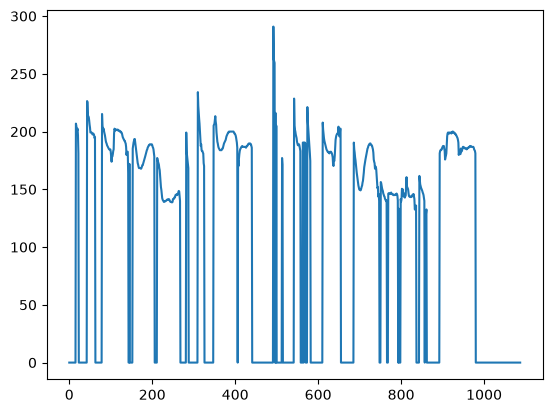

In [8]:
x, Fs = sf.read("vocal.wav")

N = 1024

hop = N//4

num_windows = len(x) // hop

pitch = np.zeros(num_windows)

start = 0

w = 0

while start + N < len(x):
    diff = CMNDF(x[start:start + N], N)
    T = period(diff, 0.6)
    if T > Fs / 500:
        pitch[w] = Fs / T
    else:
        pitch[w] = 0
    
    start += hop
    w += 1

fig, ax = plt.subplots()

names = [ "C", "Db", "D", "Eb", "E", "F", "F#", "G", "Ab", "A", "Bb", "B" ]

for freq in pitch:
    if freq != 0:
        note = int((np.log2(freq / 440.0) * 12) + 69)
        octave = note // 12
        note_name = note % 12
        print(names[note_name], octave)

ax.plot(pitch)

plt.show()

Audio(x, rate=Fs)

## Pitch Shifting

Now that we have our pitch tracking complete, we now move on to pitch shifting. Because we are working on a window to window basis, I opted to use a phase vocoding approach as opposed to a PSOLA as the pitch periods required for shifting need an analysis of the whole array while a phase-vocoder only needs access to a window. This also works better with my intentions to implement with in real-time on the Daisy Seed

To achieve this pitch shifting, I have implemented the phase vocoder from [this paper](https://www.ee.columbia.edu/~dpwe/papers/LaroD99-pvoc.pdf).

A small thing to note. Because I am applying a pitch shift, this applies non linear shift to the FFT bins which requires more involved phase adjustments to maintain phase continuity. The phase adjustments need to be calculated per bin based on the amount of bins shifted (does not need to be an integer amount). This pitch shifting does lead to some phasiness / transient smoothing in less tonal areas of the signal but this can be managed by the Yin algorithm ignoring non-tonal parts of the incoming sound.  

In [9]:
# Hermite inteprolation to interpolate values between FFT bins
def interpolate(x : np.ndarray, pos : float):
    if pos < 0 or pos > len(x):
        return 0

    # Hermite Interpolation (adapted from DaisySP delayline)
    integral   = int(pos)
    fractional = pos - integral

    xm1 = x[(integral - 1 + len(x)) % len(x)]
    x0  = x[(integral     + len(x)) % len(x)]
    x1  = x[(integral + 1 + len(x)) % len(x)]
    x2  = x[(integral + 2 + len(x)) % len(x)]

    c = (x1 - xm1) * 0.5
    v = x0 - x1
    w = c + v
    a = w + v + (x2 - x0) * 0.5
    b_neg = w + a
    f = fractional

    return (((a * f) - b_neg) * f + c) * f + x0 # the interpolated sample

# Returns pitch shifted version of the current window
def phase_vocode(x : np.ndarray, N : int, hop : int, pitch_shift : float, win : np.ndarray, phs_accu : np.ndarray):
    # FFT
    X = np.fft.rfft(x[:N], N)

    new_X = np.zeros(N//2 + 1).astype(complex)
    del_omega = np.zeros(N//2 + 1)

    # shifting bins and interpolating + calculating delta omega per bin
    for n in range(N//2 + 1):
        new_X[n] = interpolate(X, n / pitch_shift)
        del_omega[n] = ((n * pitch_shift) - n) * 2.0 * np.pi / N

    phs_adjust = (phs_accu + (del_omega * hop)) % (2.0 * np.pi)

    # Recombining polar coords into complex numbers
    new_X *= np.exp(1j * phs_adjust)

    # IFFT
    return np.fft.irfft(new_X, N), phs_adjust

In [10]:
def robot(x : np.ndarray, period : int):
    X = np.fft.rfft(x, period)
    new_X = np.abs(X)
    return np.fft.irfft(new_X, period)

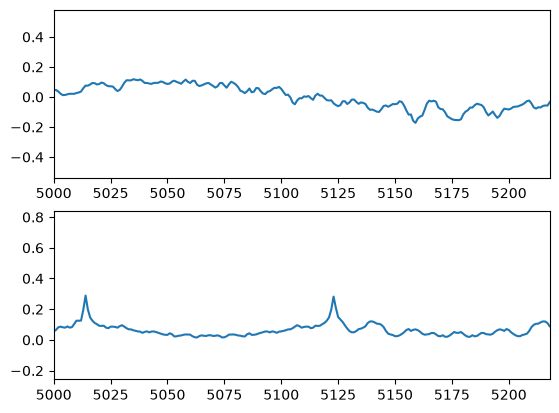

In [11]:
x, Fs = sf.read("vocal.wav")

freq = 440

N = int(Fs / freq)

y = np.zeros(len(x))

start = 0

win = np.hanning(N)

phs_accu = np.zeros(N//2 + 1)

while start + N < len(x):
    # y_new, phs_accu = phase_vocode(x[start:start + N], N, hop, 1.1, win, phs_accu)

    y_new = robot(x[start:start + N], N)

    y[start:start + N] += y_new.real

    start += N

fig, ax = plt.subplots(2)

x_start = 5000

ax[0].plot(x)
ax[0].set_xlim(x_start, x_start + 2 * N)

ax[1].plot(y)
ax[1].set_xlim(x_start, x_start + 2 * N)

plt.show()

Audio(y, rate=Fs)

## Pitch Quantizer

The last thing we need is a way to determine our desired note and subsequent pitch shift to get that autotune sound. 

For this, I will create an array of all notes and then create a function to find the nearest based on an input value. 

In [12]:
NOTE_ARRAY = np.zeros(128)

for n in range(128):
    NOTE_ARRAY[n] = 440.0 * np.pow(2, (n - 69.0) / 12.0)

def find_nearest(array : np.ndarray, value, valid_idx : np.ndarray):
    idx = 0;
    min_diff = array[len(array) - 1];
    for i in range(len(array)):
        if (i % 12) not in valid_idx:
            continue
        diff = abs(value - array[i])
        if diff < min_diff:
            min_diff = diff
            idx = i
    return array[idx]

In [13]:
def mtof(midi):
    return 440. * pow(2.0, (69. - midi) / 12.)

# Autotune!

Now to put all the pieces together and create AUTOTUNE!

In [14]:
x, Fs = sf.read("vocal.wav")

x = x.flatten("F")[:len(x)]

N = 1024

hop = N // 4

num_windows = len(x) // hop

y = np.zeros(len(x))

start = 0

win = np.hanning(N)

phs_accu = np.zeros(N//2 + 1)

valid_notes = (np.array([0, 2, 4, 5, 7, 9, 11]) + 4) % 12

notes = [440., mtof(64), mtof(67), mtof(71)]

while start + N < len(x):
    diff = CMNDF(x[start:start + N], N)
    T = period(diff, 0.6)
    if T > 50:
        pitch = Fs / T
        target = find_nearest(NOTE_ARRAY, pitch, valid_notes)
        y_new, phs_accu = phase_vocode(x[start:start + N], N, hop, target / pitch, win, phs_accu)
    else:
        y_new, phs_accu = phase_vocode(x[start:start + N], N, hop, 1, win, phs_accu)

    y[start:start + N] += y_new.real * win * win # applying the window again seems to smooth 
    
    start += hop    

Audio(y, rate=Fs)

# Real-Time Application

I decided this wasn't enough of a struggle and I went ahead and implemented autotune on the Electrosmith Daisy Seed, a little microcontroller dev board designed for audio. It is unfortunately quite slow (CPU clocks at 480MHz) and I am bad at optimizing so I've had to slow her down to around a 16kHz sampling rate. Despite this, I did successfully implement autotune on the Seed. This required my own implementation of FFT, and some awkward windowing math. The rest mostly stayed the same with a couple tweaks. Mostly it was trial and error as C++ is often very frustrating. 